# Member segmentation for a sports club
**Question.** Are there distinct kinds of members, based on how they use the club, so staff can send the right message to each group?

**Data.** Synthetic table of 1,500 members (`make_data.py`): visits per month, tenure, classes, guest passes, and spend. No real member appears. The groups are planted in the data, so this shows the method works and does not describe a real club.

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA
plt.rcParams.update({"figure.dpi": 130, "axes.spines.top": False, "axes.spines.right": False})
d = pd.read_csv("data/members_behavior.csv")
cols = [c for c in d.columns if c != "member_id"]
d[cols].describe().round(1)

,visits_per_month,tenure_months,classes_per_month,guest_passes_per_month,avg_spend_per_month
count,1500.0,1500.0,1500.0,1500.0,1500.0
mean,7.0,20.7,1.7,0.6,80.2
std,5.6,12.2,1.4,0.7,22.7
min,0.0,1.0,0.0,0.0,26.5
25%,2.5,11.0,0.5,0.0,63.0
50%,5.3,21.0,1.6,0.4,78.6
75%,10.7,29.0,2.7,1.0,97.1
max,26.3,61.0,7.1,3.1,158.2


## 1. Choose the number of groups
I try 2 to 8 clusters and look at the silhouette score (higher means cleaner separation) and the elbow in inertia.

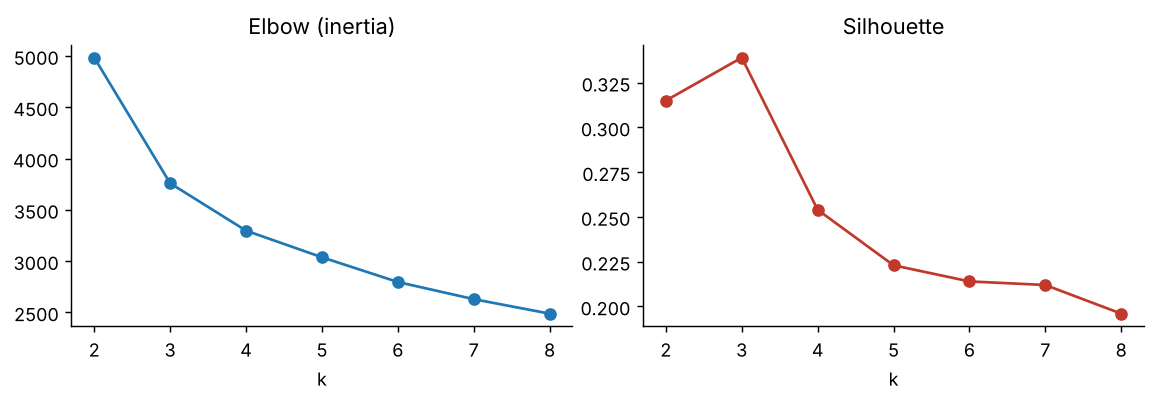

,k,inertia,silhouette
0,2,4983.994,0.315
1,3,3759.094,0.339
2,4,3296.911,0.254
3,5,3037.479,0.223
4,6,2796.219,0.214
5,7,2629.217,0.212
6,8,2487.843,0.196


In [2]:
X = StandardScaler().fit_transform(d[cols])
rows = []
for k in range(2, 9):
    km = KMeans(n_clusters=k, n_init=10, random_state=630).fit(X)
    rows.append((k, km.inertia_, silhouette_score(X, km.labels_)))
sel = pd.DataFrame(rows, columns=["k", "inertia", "silhouette"]).round(3)
fig, ax = plt.subplots(1, 2, figsize=(9, 3.2))
ax[0].plot(sel.k, sel.inertia, marker="o"); ax[0].set_title("Elbow (inertia)"); ax[0].set_xlabel("k")
ax[1].plot(sel.k, sel.silhouette, marker="o", color="#c0392b"); ax[1].set_title("Silhouette"); ax[1].set_xlabel("k")
plt.tight_layout(); plt.savefig("figures/fig1_choose_k.png"); plt.show()
sel

## 2. Fit and describe the groups

In [3]:
K = int(sel.loc[sel.silhouette.idxmax(), "k"])
km = KMeans(n_clusters=K, n_init=10, random_state=630).fit(X)
d["cluster"] = km.labels_
prof = d.groupby("cluster")[cols].mean().round(1)
prof["members"] = d.cluster.value_counts().sort_index()
prof["share_%"] = (prof.members / len(d) * 100).round(0)
print("chosen k =", K)
prof

chosen k = 3


,visits_per_month,tenure_months,classes_per_month,guest_passes_per_month,avg_spend_per_month,members,share_%
cluster,,,,,,,
0,14.3,30.3,2.9,0.3,100.0,390,26.0
1,3.1,14.1,1.5,0.3,63.5,782,52.0
2,7.4,24.9,0.8,1.5,96.5,328,22.0


## 3. Name the groups and plot them
Names below are my reading of the profile table (visits, classes, guest passes, spend). Check them against the numbers above if you re-run with different data.

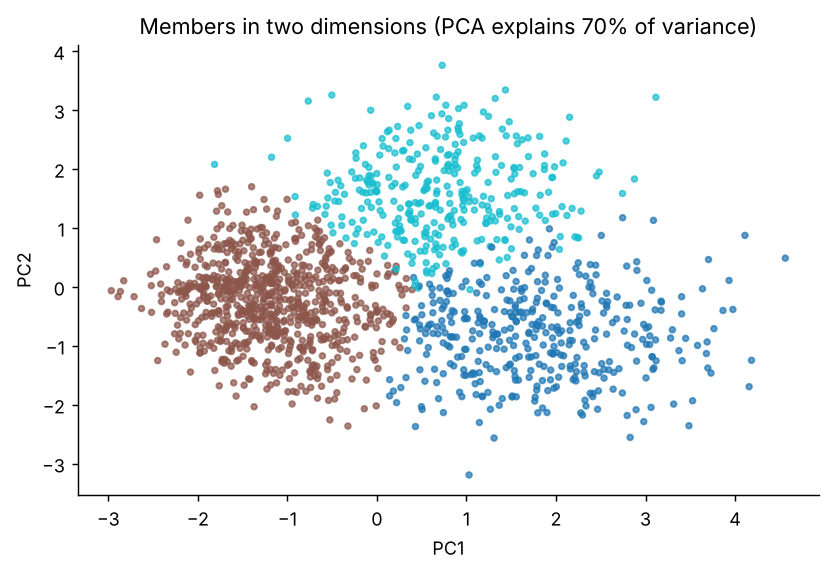

In [4]:
pca = PCA(n_components=2, random_state=630).fit(X)
Z = pca.transform(X)
fig, ax = plt.subplots(figsize=(6.5, 4.5))
sc = ax.scatter(Z[:, 0], Z[:, 1], c=d.cluster, cmap="tab10", s=10, alpha=0.7)
ax.set_title(f"Members in two dimensions (PCA explains {pca.explained_variance_ratio_.sum():.0%} of variance)")
ax.set_xlabel("PC1"); ax.set_ylabel("PC2")
plt.tight_layout(); plt.savefig("figures/fig2_clusters_pca.png"); plt.show()

## 4. How a club could use this
* Groups with high visits and many classes are the core: protect them and ask for referrals.
* Groups with few visits and short or declining engagement are the retention risk: send a friendly check-in.
* Groups heavy on guest passes are social members: offer group or event packages.

**Limits.** Synthetic data with planted groups, so real clubs will show messier, overlapping segments. Clusters describe behavior, not who someone is, and should guide outreach, never penalties.